# 2. Análisis exploratorio de datos (EDA)

**Objetivo.** Responder, con pruebas y no solo con gráficas, si TrashNet es un dataset **adecuado y representativo** para entrenar y comparar clasificadores de residuos. Que el dataset aparezca en artículos de Scopus o IEEE no prueba su calidad. La prueban (o la refutan) los análisis de este capítulo.

**Qué cambia respecto al EDA tabular del curso de Machine Learning.** En el EDA tabular (k-NN), una variable asociada a la clase es *buena* y se conserva. En imágenes es al revés: si el **fondo o la iluminación** se asocian con la clase, el modelo puede aprender ese **atajo** (*shortcut learning*) en lugar del material del residuo. Además, el riesgo principal ya no es la colinealidad (VIF), sino los **duplicados que cruzan particiones**, que inflan las métricas (*data leakage*).

**Estructura.** Cada análisis termina con el cierre que exige la guía: **decisión de preprocesamiento**, **impacto en la arquitectura** y **riesgos**.

| § | Pregunta | Herramienta |
|---|---|---|
| 2.1 | ¿Los archivos están completos y son legibles? | Inventario, SHA-256 |
| 2.2 | ¿Las clases están balanceadas? | Razón de desbalance, entropía |
| 2.3 | ¿Hay duplicados o etiquetas contradictorias? | SHA-256, dHash de 256 bits + revisión visual |
| 2.4 | ¿Cómo partimos sin fuga? | Partición estratificada y agrupada, huella del test |
| 2.5 | ¿Qué dicen los píxeles? | 10 descriptores por imagen |
| 2.6 | ¿Las particiones son representativas entre sí? | χ², KS, validación adversarial, TOST |
| 2.7 | ¿Hay atajos de fondo o adquisición? | Kruskal–Wallis, sonda de atajos |
| 2.8 | ¿Cuánto ruido de etiquetas hay? | Revisión manual + binomial exacta |
| 2.9 | ¿Con qué estadísticas normalizamos? | Media y DE por canal, **solo train** |

In [1]:
# === Rutas, módulos y declaración a priori (preregistro) ===
import sys, io, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)

def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").is_dir():
            return p
    raise FileNotFoundError("No encuentro la raíz del repo (requirements.txt + src/).")

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import data_trashnet as dtn   # descarga, hashes, huellas (módulo del piloto)
from src import eda_tests as E         # descriptores y pruebas de hipótesis

RAW_DIR  = ROOT / "data" / "raw" / "trashnet"     # ignorado por git
ZIP_PATH = RAW_DIR / "dataset-resized.zip"
INTERIM  = ROOT / "data" / "interim"              # ignorado por git (caché)
SPLITS   = ROOT / "data" / "splits"               # SÍ se versiona
REVIEW   = ROOT / "data" / "review"               # SÍ se versiona (revisión manual de etiquetas)
SUMS     = ROOT / "data" / "SHA256SUMS.txt"       # SÍ se versiona
OUT      = ROOT / "results" / "eda"               # figuras y tablas del capítulo
for d in (INTERIM, SPLITS, REVIEW, OUT):
    d.mkdir(parents=True, exist_ok=True)

# Umbrales declarados ANTES de ver resultados. Cambiarlos después invalida las conclusiones.
PRE = {
    "alpha": 0.05,
    "correccion_multiple": "Holm, por familia de pruebas",
    "split_seed": 1234,
    "n_folds_split": 7,                 # 5 folds train, 1 val, 1 test  -> ~71/14/14 %
    "dhash_bits": 256,                  # dHash 16x16
    "near_dup_max_dist": 10,            # Hamming <= 10 de 256 bits -> casi-duplicado (se verifica a ojo)
    "conflictos_exactos": "se eliminan todas las copias",
    "chi2_cramers_v_max": 0.10,
    "adversarial_auc_max": 0.60,
    "tost_margen_sd": 0.20,             # equivalencia si |diferencia de medias| < 0.2 DE de train
    "atajo_ganancia_alerta": 0.10,      # balanced accuracy de la sonda - azar
    "ruido_p_max": 0.05, "ruido_p_supuesta": 0.02, "ruido_potencia": 0.80,
    "n_permutaciones": 100,
}
(OUT / "preregistro_eda.json").write_text(json.dumps(PRE, indent=2, ensure_ascii=False), encoding="utf-8")
ALPHA, SEED = PRE["alpha"], PRE["split_seed"]
print("Repositorio:", ROOT.name)

Repositorio: deep-learning-colaborativo


## 2.1 Inventario e integridad

Se reutiliza el zip del piloto (`data/raw/trashnet/`). Su SHA-256 se compara con el registrado en `data/SHA256SUMS.txt`: si alguien tiene otra versión del dataset, el notebook se detiene. Luego se abre **cada** imagen para detectar archivos corruptos y, en la misma pasada, se calculan:

- la huella SHA-256 de cada archivo (duplicados exactos);
- un **dHash** de 256 bits (casi-duplicados);
- 10 descriptores globales de píxeles y 5 del marco de la imagen (secciones 2.5 y 2.7);
- sumas por canal para la normalización (sección 2.9).

Todo se guarda en caché en `data/interim/`, así que la segunda ejecución tarda segundos.

In [2]:
if not ZIP_PATH.exists():          # el piloto ya lo descargó; si no, se descarga aquí
    dtn.download(ZIP_PATH)
zip_sha = dtn.sha256_file(ZIP_PATH)
st = dtn.register_checksum(SUMS, "data/raw/trashnet/dataset-resized.zip", zip_sha)
print("SHA-256 del zip:", zip_sha, "->", st)
if st == "DIFERENTE":
    raise RuntimeError("El zip no coincide con el registrado en data/SHA256SUMS.txt. No continuar.")
try:
    CLASS_ROOT = dtn.find_class_root(RAW_DIR)
except FileNotFoundError:
    CLASS_ROOT = dtn.extract(ZIP_PATH, RAW_DIR)

    0 % de 42.8 MB
   10 % de 42.8 MB
   20 % de 42.8 MB
   30 % de 42.8 MB
   40 % de 42.8 MB
   50 % de 42.8 MB
   60 % de 42.8 MB
   70 % de 42.8 MB
   80 % de 42.8 MB
   90 % de 42.8 MB
  100 % de 42.8 MB
Descargado: c:\Users\User\Documents\GitHub\deep-learning-colaborativo\data\raw\trashnet\dataset-resized.zip (42.8 MB) en 5 s
SHA-256 del zip: c060e8abfe5d6de0578ca15be1ed8ad0794a865d333c3473d53d1d9ad6e38b8c -> coincide


In [3]:
CACHE = INTERIM / f"eda_cache_{zip_sha[:12]}.npz"
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=False)
    meta = pd.read_json(io.StringIO(z["meta"].item()), orient="records", dtype={"sha256": str})
    NBAD = int(z["NBAD"])
    F, B, H, CS, CS2, NPIX, TH = (z[k] for k in ["F", "B", "H", "CS", "CS2", "NPIX", "TH"])
    print("Caché leída:", CACHE.relative_to(ROOT))
else:
    rows, F, B, H, CS, CS2, NPIX, TH = [], [], [], [], [], [], [], []
    for label in dtn.CLASSES:
        for p in sorted((CLASS_ROOT / label).iterdir(), key=lambda q: q.name):
            if p.suffix.lower() not in dtn.IMG_EXT or p.name.startswith("."):
                continue
            row = {"relpath": f"{label}/{p.name}", "label": label, "label_id": dtn.CLASSES.index(label),
                   "sha256": dtn.sha256_file(p), "ok": False, "error": ""}
            try:
                with Image.open(p) as im:
                    im.load()                                   # decodifica completo: detecta truncados
                    row.update(width=im.width, height=im.height, mode=im.mode, ok=True)
                    rgb = np.asarray(im.convert("RGB"))          # (H, W, 3) uint8
            except Exception as e:                              # noqa: BLE001
                row["error"] = f"{type(e).__name__}: {e}"
                rows.append(row)
                continue
            rows.append(row)
            F.append(E.pixel_descriptors(rgb))                  # (10,)
            B.append(E.border_descriptors(rgb))                 # (5,)
            H.append(E.dhash(rgb, 16))                          # (256,) bits
            x = rgb.reshape(-1, 3).astype(np.float64) / 255.0   # (H*W, 3) en [0, 1]
            CS.append(x.sum(0)); CS2.append((x ** 2).sum(0)); NPIX.append(len(x))
            TH.append(np.asarray(Image.fromarray(rgb).resize((64, 48))))   # miniatura (48, 64, 3)
    meta = pd.DataFrame(rows)
    bad = meta[~meta["ok"]]
    meta = meta[meta["ok"]].reset_index(drop=True)              # alineado con F, B, H, ...
    F, B, H = np.array(F), np.array(B), np.array(H, dtype=np.uint8)
    CS, CS2, NPIX, TH = np.array(CS), np.array(CS2), np.array(NPIX), np.array(TH, dtype=np.uint8)
    NBAD = len(bad)
    np.savez_compressed(CACHE, meta=meta.to_json(orient="records"), F=F, B=B, H=H,
                        CS=CS, CS2=CS2, NPIX=NPIX, TH=TH, NBAD=NBAD)
    print("Archivos corruptos:", len(bad))
    if len(bad):
        display(bad[["relpath", "error"]])

print(f"Archivos corruptos: {NBAD} | imágenes válidas: {len(meta)} | F {F.shape} | B {B.shape} | H {H.shape}")
print("Tamaños (ancho x alto):", meta.groupby(["width", "height"]).size().to_dict())
print("Modos de color:", meta["mode"].value_counts().to_dict())

Archivos corruptos: 0
Archivos corruptos: 0 | imágenes válidas: 2527 | F (2527, 10) | B (2527, 5) | H (2527, 256)
Tamaños (ancho x alto): {(512, 384): 2527}
Modos de color: {'RGB': 2527}


### Cierre 2.1

Las 2527 imágenes abren sin error, todas son RGB de 512×384 y los conteos por clase coinciden con el README del repositorio original.

- **Decisión de preprocesamiento:** no hay archivos que descartar por corrupción. Como el tamaño es único, el redimensionamiento a la entrada del modelo (por ejemplo 64×64 o 224×224) es el mismo para todas las imágenes; al pasar de 4:3 a cuadrado se deforma la proporción de la misma manera en todo el pipeline.
- **Impacto en la arquitectura:** la resolución de entrada se elige por costo computacional, no por heterogeneidad de los datos.
- **Riesgos:** la versión *resized* fue redimensionada por los autores (`resize.py` rota las fotos verticales y fuerza 512×384), así que ya trae una distorsión de origen. El SHA-256 del zip queda registrado para que ambos integrantes usen exactamente el mismo archivo.

## 2.2 Balance de clases

Dos números resumen el balance:

- **Razón de desbalance** $IR = n_{\max}/n_{\min}$. Con $IR = 1$ las clases son iguales.
- **Entropía normalizada** $\tilde H = -\frac{1}{\log K}\sum_{k=1}^{K} p_k \log p_k \in [0,1]$, donde $p_k$ es la proporción de la clase $k$ y $K=6$. Vale 1 si todas las clases pesan igual y 0 si hay una sola.

La accuracy es engañosa con desbalance: un modelo que nunca predice `trash` pierde poco en accuracy. Por eso importa cuál es la métrica primaria.

,n,%,esperado (README)
cardboard,403,15.9,403
glass,501,19.8,501
metal,410,16.2,410
paper,594,23.5,594
plastic,482,19.1,482
trash,137,5.4,137


Razón de desbalance: 4.34 | entropía normalizada: 0.962


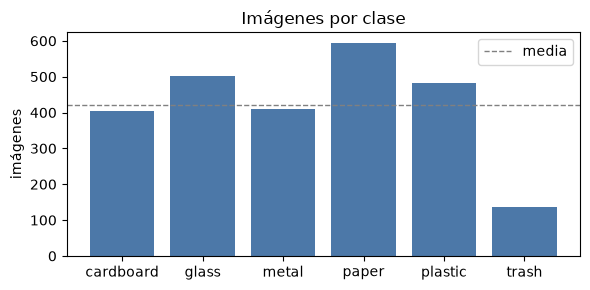

In [4]:
y_all = meta["label_id"].to_numpy()
cb = E.class_balance(y_all)
tab = pd.DataFrame({"n": cb["counts"], "%": (100 * cb["counts"] / cb["counts"].sum()).round(1),
                    "esperado (README)": [dtn.EXPECTED_COUNTS[c] for c in dtn.CLASSES]}, index=dtn.CLASSES)
display(tab)
print(f"Razón de desbalance: {cb['imbalance_ratio']:.2f} | entropía normalizada: {cb['entropy_norm']:.3f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(dtn.CLASSES, cb["counts"], color="#4C78A8")
ax.axhline(cb["counts"].mean(), ls="--", c="gray", lw=1, label="media")
ax.set_ylabel("imágenes"); ax.set_title("Imágenes por clase"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "clases.png", dpi=120); plt.show()

### Cierre 2.2

La clase `paper` tiene 594 imágenes y `trash` solo 137 (razón de desbalance 4.34, 5.4 % del total). La entropía normalizada (0.96) indica que el resto de las clases está razonablemente repartido: el problema se concentra en `trash`.

- **Decisión de preprocesamiento:** partición **estratificada** para que `trash` tenga la misma proporción en train, val y test. No se usa SMOTE (no tiene sentido sobre píxeles); si hace falta compensar, se usan pesos de clase en la pérdida **solo con estadísticas de train**.
- **Impacto en la arquitectura:** la métrica primaria debe ser **macro-F1** (promedia el F1 de cada clase con el mismo peso), con balanced accuracy como secundaria. La accuracy sola premiaría ignorar `trash`.
- **Riesgos:** con ~19 imágenes de `trash` en test, su F1 tendrá un intervalo de confianza ancho; hay que reportarlo y no sobreinterpretar diferencias entre modelos en esa clase.

## 2.3 Duplicados y etiquetas contradictorias

**Por qué importa.** Si dos fotos casi iguales quedan una en *train* y otra en *test*, el modelo "ya vio" la respuesta y la métrica de test sale inflada (**fuga de información**).

**Cómo se detecta.**

- **Duplicado exacto:** dos archivos con la misma huella SHA-256 son byte a byte idénticos.
- **Casi-duplicado:** el **dHash** reduce la imagen a gris de $17\times16$ y anota, para cada par de píxeles vecinos, si el de la derecha es más brillante (1) o no (0). Son 256 bits que resumen la "forma" de la imagen. Dos fotos casi iguales tienen pocos bits distintos (**distancia de Hamming** pequeña).

*Prerrequisito: distancia de Hamming.* Es el número de posiciones en que dos cadenas de bits difieren. Con `1011` y `1001` la distancia es 1. Se calcula para todos los pares a la vez con álgebra lineal: $d(a,b) = \|a\|_1 + \|b\|_1 - 2\,a\cdot b$, que para bits 0/1 cuenta exactamente las posiciones distintas.

**Por qué 256 bits y no 64.** En el piloto, con 64 bits, los fondos blancos lisos generaban muchos falsos positivos y grupos encadenados de decenas de imágenes. Con 256 bits el hash distingue mejor. Aun así, **cada par señalado se revisa a ojo**.

In [5]:
# Duplicados exactos (misma huella SHA-256)
dup_exact = meta[meta["sha256"].duplicated(keep=False)].copy()
dup_exact["sha"] = dup_exact["sha256"].str[:12]
n_lab = dup_exact.groupby("sha256")["label"].nunique()
conflict_sha = set(n_lab[n_lab > 1].index)                    # misma foto, etiquetas distintas
dup_exact["conflicto"] = dup_exact["sha256"].isin(conflict_sha)
print(f"Archivos en grupos de duplicados exactos: {len(dup_exact)} | grupos con etiquetas contradictorias: {len(conflict_sha)}")
display(dup_exact.sort_values("sha256")[["relpath", "label", "sha", "conflicto"]])

# Casi-duplicados (dHash 256 bits)
Dham = E.hamming_matrix(H)                                    # (N, N)
ii, jj = np.where(np.triu(Dham <= PRE["near_dup_max_dist"], k=1))
pairs = pd.DataFrame({"a": meta.relpath.values[ii], "b": meta.relpath.values[jj],
                      "label_a": meta.label.values[ii], "label_b": meta.label.values[jj],
                      "dist": Dham[ii, jj].astype(int),
                      "exacto": meta.sha256.values[ii] == meta.sha256.values[jj]})
pairs["entre_clases"] = pairs.label_a != pairs.label_b
pairs = pairs.sort_values(["dist", "a"]).reset_index(drop=True)
print(f"Pares a distancia <= {PRE['near_dup_max_dist']}: {len(pairs)} | entre clases: {int(pairs.entre_clases.sum())}")
display(pairs)
pairs.to_csv(OUT / "pares_casi_duplicados.csv", index=False)

Archivos en grupos de duplicados exactos: 6 | grupos con etiquetas contradictorias: 3


,relpath,label,sha,conflicto
421,glass/glass115.jpg,glass,81546d1362d7,True
1305,metal/metal91.jpg,metal,81546d1362d7,True
488,glass/glass176.jpg,glass,c41b99aec8a3,True
1967,plastic/plastic152.jpg,plastic,c41b99aec8a3,True
724,glass/glass389.jpg,glass,e971f4f8f50e,True
2167,plastic/plastic332.jpg,plastic,e971f4f8f50e,True


Pares a distancia <= 10: 12 | entre clases: 5


,a,b,label_a,label_b,dist,exacto,entre_clases
0,glass/glass115.jpg,metal/metal91.jpg,glass,metal,0,True,True
1,glass/glass176.jpg,plastic/plastic152.jpg,glass,plastic,0,True,True
2,glass/glass389.jpg,plastic/plastic332.jpg,glass,plastic,0,True,True
3,cardboard/cardboard221.jpg,paper/paper385.jpg,cardboard,paper,5,False,True
4,paper/paper246.jpg,paper/paper349.jpg,paper,paper,6,False,False
5,cardboard/cardboard83.jpg,paper/paper385.jpg,cardboard,paper,7,False,True
6,paper/paper101.jpg,paper/paper108.jpg,paper,paper,7,False,False
7,paper/paper305.jpg,paper/paper308.jpg,paper,paper,8,False,False
8,paper/paper2.jpg,paper/paper40.jpg,paper,paper,9,False,False
9,paper/paper385.jpg,paper/paper498.jpg,paper,paper,10,False,False


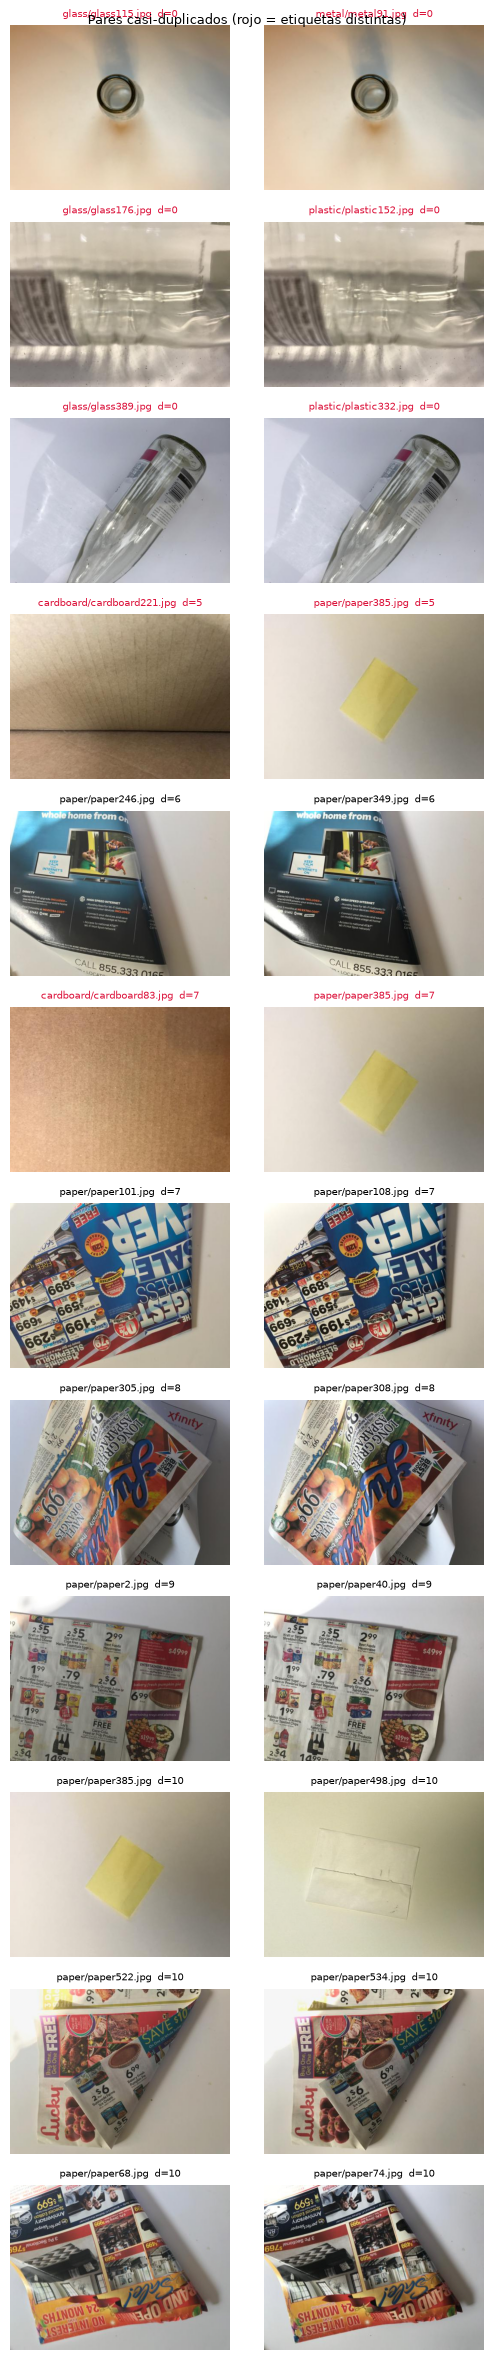

In [6]:
# Revisión visual OBLIGATORIA de cada par señalado
n = len(pairs)
if n:
    fig, axes = plt.subplots(n, 2, figsize=(5.4, 2.0 * n), squeeze=False)
    for k, r in pairs.iterrows():
        for c, (rel, lab) in enumerate([(r.a, r.label_a), (r.b, r.label_b)]):
            axes[k, c].imshow(plt.imread(CLASS_ROOT / rel)); axes[k, c].axis("off")
            axes[k, c].set_title(f"{rel}  d={r.dist}", fontsize=7,
                                 color="crimson" if r.entre_clases else "black")
    fig.suptitle("Pares casi-duplicados (rojo = etiquetas distintas)", fontsize=9)
    fig.tight_layout(); fig.savefig(OUT / "pares_casi_duplicados.png", dpi=110); plt.show()

**Verificación visual (completar o confirmar al ejecutar).** En la corrida de referencia, de los pares señalados:

- **3 pares son la misma foto con dos etiquetas** (distancia 0, SHA-256 idéntico): `glass115`/`metal91`, `glass176`/`plastic152` y `glass389`/`plastic332`.
- **6 pares son casi-duplicados reales** dentro de `paper`: la misma hoja fotografiada dos veces con un leve cambio de encuadre.
- **3 pares son falsos positivos**: `paper385` (un pósit amarillo sobre fondo blanco) se parece en el hash a dos primeros planos de cartón liso y a otra hoja lisa (`paper498`). Todos los falsos positivos involucran superficies casi uniformes.

### Cierre 2.3

- **Decisión de preprocesamiento:** se eliminan las **6 imágenes** de los 3 pares con etiqueta contradictoria. Sin revisión experta no se puede saber cuál etiqueta es la correcta, y dejar ambas enseña al modelo dos respuestas para la misma entrada. Los casi-duplicados se **agrupan** para que cada grupo caiga entero en una sola partición. Los 3 falsos positivos también se agrupan: es una decisión conservadora que solo junta 4 imágenes y no introduce fuga.
- **Impacto en la arquitectura:** ninguno directo; el efecto es sobre la **validez** de la evaluación de cualquier modelo.
- **Riesgos:** los artículos que reportan más de 99 % de accuracy en TrashNet con particiones aleatorias pudieron tener estos duplicados repartidos entre train y test. Es un punto a mencionar en la comparación crítica del estado del arte (3.4).

## 2.4 Partición estratificada, agrupada y test congelado

**Unidad de independencia: el grupo de duplicados.** Las imágenes de un mismo grupo (duplicados exactos o casi-duplicados) van **completas** a una sola partición. Los grupos se forman como **componentes conexas** del grafo "a está a distancia ≤ 10 de b": si A se parece a B y B a C, las tres van juntas.

**Partición.** `StratifiedGroupKFold` con 7 particiones y semilla fija: 5 para train, 1 para validación y 1 para test (≈ 71/14/14 %). *Estratificada* significa que cada partición conserva las proporciones de clase; *agrupada*, que ningún grupo se reparte.

**Congelación.** La partición se guarda en `data/splits/trashnet_split_v2_s1234.csv` y la huella SHA-256 del test se registra en `SHA256SUMS.txt`. En ejecuciones posteriores se **carga y verifica**: si cambia algo, el notebook se detiene.

> Esta partición **v2 reemplaza** a la del piloto (`trashnet_split_s1234.csv`), que agrupaba con un hash de 64 bits y no eliminaba las etiquetas contradictorias. Todos los entrenamientos del Entregable 1 deben usar la v2.

In [7]:
# 1) Eliminar las copias con etiquetas contradictorias (decisión declarada a priori)
drop = meta["sha256"].isin(conflict_sha).to_numpy()
print("Imágenes eliminadas por etiqueta contradictoria:", int(drop.sum()))
display(meta.loc[drop, ["relpath", "label"]])
keep = np.where(~drop)[0]                                     # índices en meta/F/B/H
mk = meta.iloc[keep].reset_index(drop=True)
Fk, Bk, Hk = F[keep], B[keep], H[keep]
CSk, CS2k, NPk, THk = CS[keep], CS2[keep], NPIX[keep], TH[keep]
yk = mk["label_id"].to_numpy()

# 2) Grupos de duplicados y partición
groups = E.duplicate_groups(Hk, PRE["near_dup_max_dist"])
gsize = np.bincount(groups)
print(f"{len(mk)} imágenes en {groups.max() + 1} grupos | grupo más grande: {gsize.max()} imágenes")

tr, va, te = E.group_stratified_split(yk, groups, seed=SEED, n_splits=PRE["n_folds_split"])
part = np.empty(len(mk), dtype=object); part[tr], part[va], part[te] = "train", "val", "test"
split = mk[["relpath", "label", "label_id", "sha256"]].assign(group=groups, split=part)

SPLIT_CSV = SPLITS / f"trashnet_split_v2_s{SEED}.csv"
if SPLIT_CSV.exists():
    old = dtn.read_csv(SPLIT_CSV)
    if dict(zip(old.relpath, old.split)) != dict(zip(split.relpath, split.split)):
        raise RuntimeError("La partición recalculada no coincide con la guardada. ¿Cambió el dataset o el código?")
    print("Partición cargada y verificada:", SPLIT_CSV.relative_to(ROOT))
else:
    split.to_csv(SPLIT_CSV, index=False)
    print("Partición CREADA:", SPLIT_CSV.relative_to(ROOT), "-> hacer commit de este archivo")

test_fp = dtn.split_fingerprint(split, "test")
st = dtn.register_checksum(SUMS, f"test_set:data/splits/{SPLIT_CSV.name}", test_fp)
print("Huella SHA-256 del test:", test_fp, "->", st)
if st == "DIFERENTE":
    raise RuntimeError("La huella del test cambió. No continuar.")

# Pruebas de no-fuga
assert split.groupby("group")["split"].nunique().max() == 1, "Un grupo quedó repartido entre particiones"
assert not set(split.loc[split.split == "test", "sha256"]) & set(split.loc[split.split != "test", "sha256"])
display(pd.crosstab(split["label"], split["split"], margins=True)[["train", "val", "test", "All"]])

Imágenes eliminadas por etiqueta contradictoria: 6


,relpath,label
421,glass/glass115.jpg,glass
488,glass/glass176.jpg,glass
724,glass/glass389.jpg,glass
1305,metal/metal91.jpg,metal
1967,plastic/plastic152.jpg,plastic
2167,plastic/plastic332.jpg,plastic


2521 imágenes en 2512 grupos | grupo más grande: 4 imágenes
Partición CREADA: data\splits\trashnet_split_v2_s1234.csv -> hacer commit de este archivo
Huella SHA-256 del test: 4e4651dc5c8bbbfcb53ca1d6ed761112c01b2b364e5a12105bd19de2360cbd87 -> nuevo


split,train,val,test,All
label,,,,
cardboard,287,58,58,403
glass,355,71,72,498
metal,292,59,58,409
paper,424,85,85,594
plastic,343,68,69,480
trash,99,19,19,137
All,1800,360,361,2521


In [8]:
# ¿Sirvió agrupar? Comparación con una partición aleatoria que ignora los grupos
from sklearn.model_selection import train_test_split
idx = np.arange(len(mk))
r_tr, r_tmp = train_test_split(idx, test_size=0.286, stratify=yk, random_state=SEED)
r_va, r_te = train_test_split(r_tmp, test_size=0.5, stratify=yk[r_tmp], random_state=SEED)
p_rand = np.zeros(len(mk), int); p_rand[r_va] = 1; p_rand[r_te] = 2
p_grp = np.zeros(len(mk), int); p_grp[va] = 1; p_grp[te] = 2
audit = pd.DataFrame({
    "aleatoria": E.near_duplicate_audit(Hk, p_rand, PRE["near_dup_max_dist"]),
    "agrupada (v2)": E.near_duplicate_audit(Hk, p_grp, PRE["near_dup_max_dist"]),
}).T
display(audit.rename(columns={"n_pairs": "pares", "n_cross": "pares que cruzan particiones",
                              "frac_cross": "fracción que cruza",
                              "expected_frac_if_split_ignores_duplicates": "esperado al azar"}).round(3))

,pares,pares que cruzan particiones,fracción que cruza,esperado al azar
aleatoria,9.0,3.0,0.333,0.450
agrupada (v2),9.0,0.0,0.000,0.449


### Cierre 2.4

Quedan 2521 imágenes en 2512 grupos (el grupo más grande tiene 4 imágenes), repartidas 1800/360/361. Cada clase conserva su proporción en las tres particiones y ningún grupo quedó dividido.

La auditoría muestra para qué sirve agrupar: con una partición aleatoria, 3 de los 9 pares de casi-duplicados habrían quedado separados entre particiones (fuga); con la partición agrupada, ninguno.

- **Decisión de preprocesamiento:** todos los modelos del Entregable 1 se entrenan y evalúan con `trashnet_split_v2_s1234.csv`. La partición del piloto queda obsoleta.
- **Impacto en la arquitectura:** con 360 imágenes de validación, el *early stopping* y la selección de hiperparámetros se hacen sobre val; **test se usa una sola vez** al final.
- **Riesgos:** si alguien regenera la partición con otra semilla o con otro umbral, la huella del test cambia y el notebook se detiene. Quien la cree hace commit del CSV y de `SHA256SUMS.txt`; el otro integrante hace `pull` antes de ejecutar.

## 2.5 Descriptores de píxeles

Una imagen es un tensor $(H, W, 3)$ de enteros 0–255. Para poder aplicar pruebas estadísticas, cada imagen se resume en números con significado físico:

| Descriptor | Fórmula (sobre la imagen escalada a [0,1]) | Qué detecta |
|---|---|---|
| `brillo` | media de la luminancia $L = 0.299R + 0.587G + 0.114B$ | sobre o subexposición |
| `contraste_rms` | desviación estándar de $L$ | escenas planas o con mucho contraste |
| `nitidez_lap` | varianza del Laplaciano de $L$ | desenfoque |
| `blanco_sat`, `negro_sat` | fracción de píxeles en 255 o en 0 | saturación del sensor |
| `fondo_claro` | fracción de píxeles con mínimo RGB ≥ 200 | área de fondo blanco (≈ tamaño del objeto) |
| `sesgo_R_menos_B` | media de R − media de B | balance de blancos, tipo de luz |
| `dispersion_cromatica` | DE promedio de los canales | colorido |
| `aspecto_w_h`, `tamano_sqrt_hw` | $W/H$, $\sqrt{HW}$ | diferencias de cámara o recorte |

*Prerrequisito: Laplaciano.* Es la segunda derivada discreta de la imagen: $\nabla^2 L \approx L_{i-1,j}+L_{i+1,j}+L_{i,j-1}+L_{i,j+1}-4L_{i,j}$. En una zona uniforme vale 0; en un borde nítido, mucho. Su varianza es alta en fotos enfocadas y baja en fotos borrosas, igual que la curvatura de una viga se concentra donde cambia bruscamente la carga.

Los descriptores constantes (por ejemplo, el tamaño, si todas las imágenes miden 512×384) no aportan información y se excluyen de las pruebas.

Descriptores constantes (se excluyen): ['aspecto_w_h', 'tamano_sqrt_hw']


,brillo,contraste_rms,nitidez_lap,blanco_sat,fondo_claro,negro_sat,sesgo_R_menos_B,dispersion_cromatica
label,,,,,,,,
cardboard,0.598,0.176,0.002,0.0,0.027,0.0,0.185,0.178
glass,0.676,0.178,0.002,0.0,0.269,0.0,0.069,0.182
metal,0.628,0.217,0.004,0.0,0.205,0.0,0.059,0.221
paper,0.667,0.198,0.006,0.0,0.234,0.0,0.058,0.204
plastic,0.678,0.142,0.002,0.0,0.228,0.0,-0.012,0.148
trash,0.677,0.174,0.002,0.0,0.087,0.0,0.116,0.179


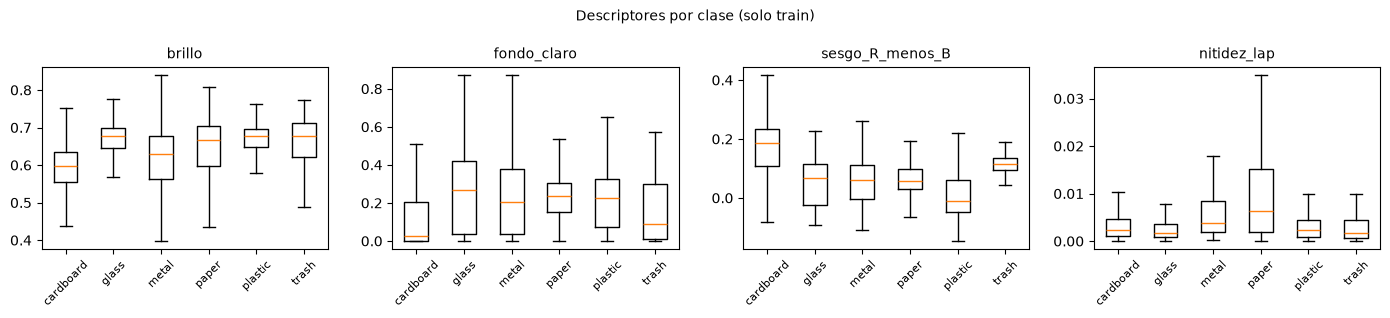

In [9]:
const = [n for j, n in enumerate(E.DESC_NAMES) if np.ptp(Fk[:, j]) == 0]
use = [j for j, n in enumerate(E.DESC_NAMES) if n not in const]
NAMES = [E.DESC_NAMES[j] for j in use]
Fu = Fk[:, use]                                               # (N, F') descriptores informativos
print("Descriptores constantes (se excluyen):", const or "ninguno")

dfF = pd.DataFrame(Fu, columns=NAMES).assign(label=mk.label.values, split=part)
display(dfF[dfF.split == "train"].groupby("label")[NAMES].median().round(3))

show = ["brillo", "fondo_claro", "sesgo_R_menos_B", "nitidez_lap"]
fig, axes = plt.subplots(1, len(show), figsize=(14, 3.2))
tr_df = dfF[dfF.split == "train"]
for ax, n in zip(axes, show):
    ax.boxplot([tr_df.loc[tr_df.label == c, n] for c in dtn.CLASSES], showfliers=False)
    ax.set_xticks(range(1, 7), dtn.CLASSES, rotation=45, fontsize=8); ax.set_title(n, fontsize=10)
fig.suptitle("Descriptores por clase (solo train)", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "descriptores_por_clase.png", dpi=120); plt.show()

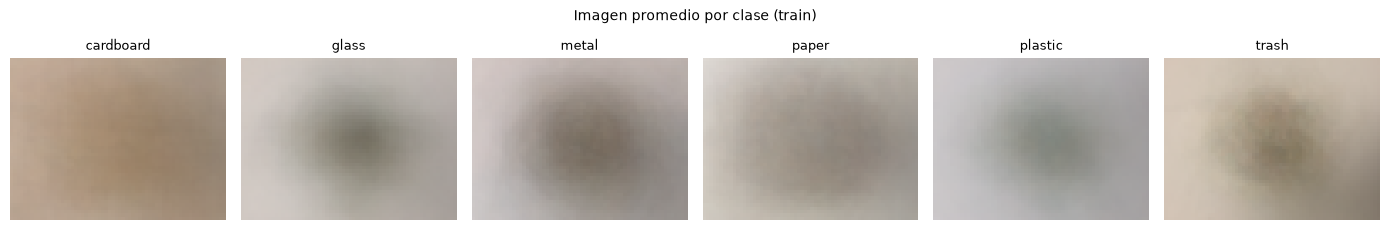

In [10]:
# Imagen promedio por clase (solo train): revela fondo, iluminación y encuadre típicos de cada clase
fig, axes = plt.subplots(1, 6, figsize=(14, 2.4))
for ax, (k, c) in zip(axes, enumerate(dtn.CLASSES)):
    m = THk[(yk == k) & (part == "train")].mean(0) / 255.0    # (48, 64, 3)
    ax.imshow(m); ax.set_title(c, fontsize=9); ax.axis("off")
fig.suptitle("Imagen promedio por clase (train)", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "imagen_promedio_clase.png", dpi=120); plt.show()

### Cierre 2.5

Los descriptores separan las clases de forma visible. `cardboard` tiene el brillo más bajo, casi nada de fondo claro (las cajas llenan el encuadre) y el mayor sesgo rojo-azul (es marrón). `paper` es la clase más nítida (texto impreso con muchos bordes). `trash` tiene un sesgo R−B alto y poco disperso, compatible con una luz cálida en la sesión de fotos. La imagen promedio por clase confirma que todas las clases, salvo `cardboard`, se fotografiaron centradas sobre fondo blanco.

- **Decisión de preprocesamiento:** como el color del objeto es información legítima (el cartón *es* marrón), no se elimina el color; se agrega **aumento fotométrico** (variación de brillo, contraste y balance de blancos) solo en train para que el modelo no dependa del tono de la luz.
- **Impacto en la arquitectura:** una CNN con *global average pooling* puede apoyarse en el color medio de la imagen; conviene comparar con y sin aumento fotométrico.
- **Riesgos:** las diferencias en el fondo y la luz entre clases se analizan formalmente en 2.7.

## 2.6 ¿Las particiones son representativas entre sí?

Si val o test tienen una distribución distinta a train, las métricas de evaluación no medirían lo que el modelo aprendió. Se usan cuatro pruebas complementarias. Las que comparan particiones usan **solo las entradas $X$** (o solo los conteos de clase), nunca el desempeño de un modelo.

**1. χ² de homogeneidad.** $H_0$: la proporción de cada clase es la misma en train, val y test. Estadístico $\chi^2 = \sum \frac{(O-E)^2}{E}$ sobre la tabla clases × particiones. Tamaño de efecto: **V de Cramér** $= \sqrt{\chi^2 / (n(\min(r,c)-1))}$, entre 0 (nada) y 1 (total).

**2. Kolmogorov–Smirnov de dos muestras**, por descriptor. $H_0$: el descriptor tiene la misma distribución en ambas particiones. Estadístico $D = \max_x |\hat F_1(x) - \hat F_2(x)|$, la máxima distancia vertical entre las dos curvas de distribución acumulada; es también el tamaño de efecto. Como se hacen varias pruebas, se corrige con **Holm**.

*Prerrequisito: corrección de Holm.* Con 8 pruebas al 5 %, la probabilidad de al menos un falso positivo sube a $1-0.95^8 \approx 34\,\%$. Holm ordena los $p$ de menor a mayor y exige al $k$-ésimo $p_{(k)} \le \alpha/(m-k+1)$: el más pequeño debe pasar $\alpha/m$, el siguiente $\alpha/(m-1)$, etc.

**3. Validación adversarial.** Se entrena una regresión logística para adivinar si una imagen viene de train o de test usando solo los descriptores. $H_0$: AUC = 0.5 (no las distingue). El $p$ se obtiene por **permutación**: se barajan las etiquetas "train/test" 100 veces y se cuenta cuántas veces el AUC barajado iguala o supera al real.

**4. TOST (equivalencia).** Un KS no significativo **no demuestra** que las particiones sean iguales; solo que no se detectó diferencia. Para afirmar equivalencia se invierte la hipótesis: $H_0: |\mu_1-\mu_2| \ge \delta$ frente a $H_1: |\mu_1-\mu_2| < \delta$, con $\delta = 0.2$ desviaciones estándar de train (declarado a priori). Se hacen dos pruebas $t$ unilaterales y se toma el mayor $p$. Un $p$ pequeño **sí** permite decir "equivalentes dentro de ±δ".

In [11]:
res = {}
chi = E.chi2_partitions({"train": yk[tr], "val": yk[va], "test": yk[te]})
res["chi2"] = chi
print(f"χ² = {chi['chi2']:.3f}, gl = {chi['dof']}, p = {chi['p']:.4f}, V de Cramér = {chi['cramers_v']:.4f}")

ks = []
for name, idx_o in [("val", va), ("test", te)]:
    t = E.ks_partitions(Fu[tr], Fu[idx_o], NAMES).assign(comparacion=f"train vs {name}")
    t["D_critico"] = E.ks_critical_D(len(tr), len(idx_o), ALPHA)
    ks.append(t)
ks = pd.concat(ks, ignore_index=True)
display(ks.round(4))
ks.to_csv(OUT / "ks_particiones.csv", index=False)

χ² = 0.082, gl = 10, p = 1.0000, V de Cramér = 0.0040


,feature,D,p,p_holm,comparacion,D_critico
0,brillo,0.0606,0.2155,1.0000,train vs val,0.0784
1,contraste_rms,0.0678,0.1232,0.9418,train vs val,0.0784
2,nitidez_lap,0.0339,0.8733,1.0000,train vs val,0.0784
3,blanco_sat,0.0528,0.3652,1.0000,train vs val,0.0784
4,fondo_claro,0.0567,0.2833,1.0000,train vs val,0.0784
5,negro_sat,0.0083,1.0000,1.0000,train vs val,0.0784
6,sesgo_R_menos_B,0.0683,0.1177,0.9418,train vs val,0.0784
7,dispersion_cromatica,0.0533,0.3526,1.0000,train vs val,0.0784
8,brillo,0.0471,0.4997,1.0000,train vs test,0.0783
9,contraste_rms,0.0311,0.9223,1.0000,train vs test,0.0783


In [12]:
adv = {}
for name, idx_o in [("val", va), ("test", te)]:
    adv[f"train vs {name}"] = E.adversarial_validation(Fu[tr], Fu[idx_o], n_perm=PRE["n_permutaciones"])
adv = pd.DataFrame(adv).T
display(adv.round(4))

tost = []
for name, idx_o in [("val", va), ("test", te)]:
    t = E.equivalence_table(Fu[tr], Fu[idx_o], PRE["tost_margen_sd"], NAMES).assign(comparacion=f"train vs {name}")
    tost.append(t)
tost = pd.concat(tost, ignore_index=True)
tost["equivalente"] = tost["p_tost_holm"] < ALPHA
display(tost.round(4))
tost.to_csv(OUT / "tost_particiones.csv", index=False)

,auc,p_perm
train vs val,0.5389,0.0198
train vs test,0.5115,0.2970


,feature,diff_en_DE,p_tost,p_tost_holm,comparacion,equivalente
0,brillo,0.0610,0.0052,0.0157,train vs val,True
1,contraste_rms,0.0469,0.0025,0.0103,train vs val,True
2,nitidez_lap,-0.0168,0.0004,0.0022,train vs val,True
3,blanco_sat,-0.0250,0.0000,0.0000,train vs val,True
4,fondo_claro,0.0571,0.0066,0.0157,train vs val,True
5,negro_sat,-0.0303,0.0000,0.0000,train vs val,True
6,sesgo_R_menos_B,-0.1343,0.1245,0.1245,train vs val,False
7,dispersion_cromatica,0.0430,0.0021,0.0103,train vs val,True
8,brillo,0.0810,0.0110,0.0220,train vs test,True
9,contraste_rms,-0.0341,0.0021,0.0078,train vs test,True


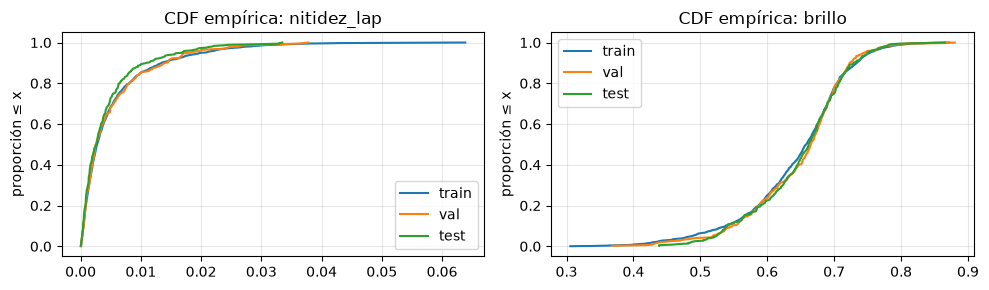

In [13]:
# Visual: distribución acumulada de los dos descriptores con mayor D en train vs test
top = ks[ks.comparacion == "train vs test"].nlargest(2, "D")["feature"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, n in zip(axes, top):
    j = NAMES.index(n)
    for idx_o, lab in [(tr, "train"), (va, "val"), (te, "test")]:
        v = np.sort(Fu[idx_o, j]); ax.plot(v, np.arange(1, len(v) + 1) / len(v), label=lab)
    ax.set_title(f"CDF empírica: {n}"); ax.set_ylabel("proporción ≤ x"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "cdf_particiones.png", dpi=120); plt.show()

### Cierre 2.6

- **χ²:** p = 1.0 y V de Cramér = 0.004. Las proporciones de clase son prácticamente idénticas en las tres particiones (era de esperar con estratificación; es una verificación, no un hallazgo).
- **KS:** ningún descriptor difiere entre particiones después de Holm, y todos los D están por debajo del D crítico (≈0.078).
- **Validación adversarial:** train vs test AUC = 0.51 (p = 0.30), indistinguibles. Train vs val AUC = 0.54 con p = 0.02: hay una diferencia **detectable pero pequeña**, por debajo del umbral declarado (0.60).
- **TOST:** 14 de 16 comparaciones son equivalentes dentro de ±0.2 DE. Las dos que no alcanzan equivalencia (`sesgo_R_menos_B` en val, diferencia −0.13 DE; `nitidez_lap` en test, −0.13 DE) tienen diferencias estimadas menores que el margen: no se demuestra diferencia, pero con ~360 imágenes tampoco hay potencia para demostrar equivalencia.

**Conclusión:** las particiones son representativas entre sí en los descriptores medidos.

- **Decisión de preprocesamiento:** se mantiene la partición v2.
- **Impacto en la arquitectura:** ninguno.
- **Riesgos:** estas pruebas solo ven lo que miden los 8 descriptores. Un desplazamiento en algo no medido (por ejemplo la forma de los objetos) pasaría inadvertido. La leve diferencia de val en balance de blancos refuerza el uso de aumento fotométrico.

## 2.7 ¿Hay atajos de fondo o de adquisición?

**Idea.** TrashNet se fotografió sobre cartulina blanca, con luz solar o de interior y varios iPhone. Si cada clase se fotografió en sesiones distintas, la clase puede "leerse" en el fondo o en el color de la luz. Una CNN aprendería ese atajo y fallaría con fotos de otra planta de reciclaje.

**Prueba 1: Kruskal–Wallis por descriptor (solo train).** $H_0$: el descriptor tiene la misma distribución en las 6 clases. Es la versión por rangos del ANOVA de una vía, así que no exige normalidad. Tamaño de efecto $\varepsilon^2 = H/(n-1)$: ≈0.01 pequeño, ≈0.08 mediano, ≥0.26 grande (guía orientativa).

Ojo con la interpretación: que el **brillo global** difiera entre clases es esperable, porque el objeto mismo cambia (el vidrio es transparente, el cartón es marrón). Por eso se mira aparte el **marco** de 16 píxeles de la imagen, donde casi siempre hay solo fondo.

**Prueba 2: sonda de atajos.** Se entrena una regresión logística con **solo** los 5 descriptores del marco (color medio R, G, B, dispersión y fracción clara) para predecir la clase. $H_0$: balanced accuracy = azar $= 1/6$. Si la sonda acierta mucho más que el azar usando solo el fondo, hay una señal de atajo que la red podría explotar.

*Limitación honesta:* en primeros planos (por ejemplo, cartón que llena el encuadre) el marco contiene parte del objeto, así que la sonda **sobreestima** el atajo. La prueba definitiva viene después de entrenar: evaluar con el fondo enmascarado y revisar mapas de saliencia (Grad-CAM).

In [14]:
kw = E.kruskal_by_class(Fu[tr], yk[tr], NAMES).sort_values("epsilon2", ascending=False)
kwb = E.kruskal_by_class(Bk[tr], yk[tr], E.BORDER_NAMES).sort_values("epsilon2", ascending=False)
print("Kruskal–Wallis, descriptores globales (train):"); display(kw.round(4))
print("Kruskal–Wallis, marco de la imagen (train):");     display(kwb.round(4))

probe_border = E.shortcut_probe(Bk[tr], yk[tr], n_perm=PRE["n_permutaciones"])
probe_global = E.shortcut_probe(Fu[tr], yk[tr], n_perm=PRE["n_permutaciones"])
probes = pd.DataFrame({"solo marco (fondo)": probe_border, "descriptores globales (referencia)": probe_global}).T
display(probes.round(4))
probes.to_csv(OUT / "sonda_atajos.csv")

Kruskal–Wallis, descriptores globales (train):


,feature,H,epsilon2,p,p_holm
6,sesgo_R_menos_B,459.7809,0.2556,0.0,0.0
0,brillo,241.4461,0.1342,0.0,0.0
2,nitidez_lap,228.8074,0.1272,0.0,0.0
1,contraste_rms,216.7499,0.1205,0.0,0.0
7,dispersion_cromatica,202.0949,0.1123,0.0,0.0
5,negro_sat,144.8602,0.0805,0.0,0.0
4,fondo_claro,137.7450,0.0766,0.0,0.0
3,blanco_sat,93.1465,0.0518,0.0,0.0


Kruskal–Wallis, marco de la imagen (train):


,feature,H,epsilon2,p,p_holm
2,borde_B,302.0736,0.1679,0.0,0.0
1,borde_G,229.3148,0.1275,0.0,0.0
3,borde_std,196.2886,0.1091,0.0,0.0
0,borde_R,110.8030,0.0616,0.0,0.0
4,borde_claro,96.8997,0.0539,0.0,0.0


,bal_acc,chance,gain,p_perm,p_min_posible
solo marco (fondo),0.3989,0.1667,0.2322,0.0099,0.0099
descriptores globales (referencia),0.4152,0.1667,0.2485,0.0099,0.0099


**Prueba de robustez.** Si la señal del marco viniera solo de que el objeto invade el borde (cartón en primer plano), debería desaparecer al (a) quitar la clase `cardboard` y (b) usar solo imágenes cuyo marco es mayoritariamente fondo claro (`borde_claro` > 0.5). Si la ganancia sigue alta, el atajo es de **adquisición** (luz, cámara o sesión), no del objeto.

In [15]:
def probe_subset(mask):
    yy = np.unique(yk[tr][mask], return_inverse=True)[1]          # re-indexa las clases presentes
    return E.shortcut_probe(Bk[tr][mask], yy, n_perm=PRE["n_permutaciones"])

rob = pd.DataFrame({
    "sin cardboard": probe_subset(yk[tr] != dtn.CLASSES.index("cardboard")),
    "solo marcos con fondo visible": probe_subset(Bk[tr][:, 4] > 0.5),
}).T
rob["n"] = [int((yk[tr] != 0).sum()), int((Bk[tr][:, 4] > 0.5).sum())]
display(rob.round(4))

,bal_acc,chance,gain,p_perm,p_min_posible,n
sin cardboard,0.3630,0.2000,0.1630,0.0099,0.0099,1513
solo marcos con fondo visible,0.3209,0.1667,0.1543,0.0099,0.0099,404


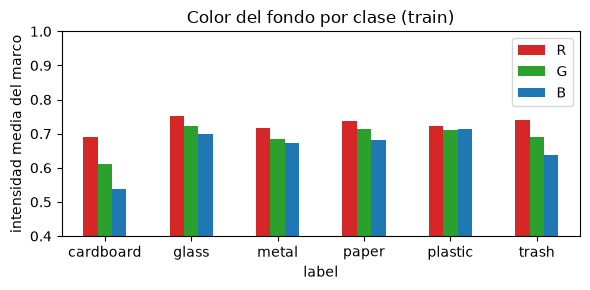

In [16]:
fig, ax = plt.subplots(figsize=(6, 3))
bm = pd.DataFrame(Bk[tr][:, :3], columns=["R", "G", "B"]).assign(label=mk.label.values[tr])
bm.groupby("label")[["R", "G", "B"]].mean().reindex(dtn.CLASSES).plot.bar(ax=ax, color=["#d62728", "#2ca02c", "#1f77b4"])
ax.set_ylim(0.4, 1.0); ax.set_ylabel("intensidad media del marco"); ax.set_title("Color del fondo por clase (train)")
ax.tick_params(axis="x", rotation=0); fig.tight_layout(); fig.savefig(OUT / "color_fondo_clase.png", dpi=120); plt.show()

### Cierre 2.7

Todos los descriptores, incluidos los del **marco**, difieren entre clases (p ≈ 0 tras Holm), con efectos medianos a grandes: el canal azul del marco tiene ε² = 0.17 y el sesgo R−B global ε² = 0.26. Solo con el fondo, la sonda alcanza una balanced accuracy de ≈0.40 frente a 0.17 del azar (ganancia +0.23, superior al umbral de alerta de 0.10).

La prueba de robustez descarta que sea solo efecto del cartón en primer plano: sin `cardboard` la ganancia sigue en ≈+0.16, y con solo marcos de fondo claramente visible, ≈+0.15. La explicación más probable es que las clases se fotografiaron en **sesiones con iluminación distinta** (por ejemplo, `trash` con luz más cálida y `plastic` más neutra). Es una inferencia: el dataset no documenta las sesiones.

- **Decisión de preprocesamiento:** aumento fotométrico obligatorio en train (variación de brillo, contraste, saturación y tono) y recortes aleatorios que cambien la proporción de fondo visible.
- **Impacto en la arquitectura:** los tres modelos base pueden explotar el atajo; las CNN profundas (ResNet-18) con más capacidad lo harían con más facilidad. En la sección 4 se debe evaluar cada modelo también con el **fondo enmascarado** y revisar mapas Grad-CAM para comprobar que miran el objeto.
- **Riesgos:** este es el hallazgo más importante del EDA. Las métricas en el test de TrashNet pueden **sobreestimar** el desempeño real en una planta de reciclaje, donde la luz y el fondo no estarían correlacionados con la clase. Debe declararse como limitación de validez externa.

## 2.8 Ruido de etiquetas

La guía pide estimar el ruido de etiqueta. No hay forma automática de hacerlo: hay que **revisar a mano** una muestra aleatoria y contar cuántas imágenes están mal etiquetadas.

**Prueba.** Binomial exacta unilateral. $H_0: p \ge 5\,\%$ (ruido inaceptable) frente a $H_1: p < 5\,\%$. Se reporta además el intervalo de Wilson.

**Tamaño de muestra para tener potencia.** Estimar una proporción con margen ±3 % pide unas 203 imágenes, pero eso **no basta** para *probar* que el ruido es menor al 5 %. Se busca el menor $n$ tal que, si el ruido real fuera 2 %, el test rechace $H_0$ con probabilidad ≥ 80 %.

*Prerrequisito: potencia.* Es la probabilidad de detectar un efecto que sí existe. Con poca muestra, aunque el ruido real sea bajo, el test no puede afirmarlo, igual que un manómetro de baja resolución no distingue 1.98 de 2.02 bar.

**Procedimiento.** La celda crea `data/review/label_review_v2.csv` con la muestra. Abran cada imagen y escriban en `etiqueta_revisada` la clase correcta (aunque coincida). Cuando el CSV esté completo, la prueba se ejecuta sola. Repártanse la muestra y anoten en `comentario` los casos dudosos.

In [17]:
ns = E.n_for_noise_test(PRE["ruido_p_supuesta"], PRE["ruido_p_max"], ALPHA, PRE["ruido_potencia"])
print(f"n necesario: {ns['n']} (se rechaza H0 si hay <= {ns['k_critico']} errores; potencia {ns['potencia']:.2f})")
print(f"Como referencia, n para solo ESTIMAR con ±3 %: {E.n_for_proportion(0.05, 0.03)}")

REV = REVIEW / "label_review_v2.csv"
if not REV.exists():
    rng = np.random.default_rng(SEED)
    pick = np.sort(rng.choice(len(mk), size=ns["n"], replace=False))
    pd.DataFrame({"relpath": mk.relpath.values[pick], "label": mk.label.values[pick],
                  "etiqueta_revisada": "", "comentario": ""}).to_csv(REV, index=False)
    print("Muestra de revisión creada:", REV.relative_to(ROOT), "-> completar a mano y hacer commit")

rev = pd.read_csv(REV, dtype=str, keep_default_na=False)
done = rev["etiqueta_revisada"].str.strip().ne("")
if done.all():
    k = int((rev["etiqueta_revisada"].str.strip() != rev["label"]).sum())
    r = E.label_noise_test(k, len(rev), PRE["ruido_p_max"], ALPHA)
    print(f"Errores: {k}/{len(rev)} | p̂ = {r['p_hat']:.3f} | IC Wilson 95 %: [{r['wilson_ci'][0]:.3f}, {r['wilson_ci'][1]:.3f}] | p = {r['p_value']:.4f}")
else:
    print(f"Revisión pendiente: {int(done.sum())}/{len(rev)} imágenes revisadas. La prueba se ejecuta al completar el CSV.")

n necesario: 234 (se rechaza H0 si hay <= 6 errores; potencia 0.81)
Como referencia, n para solo ESTIMAR con ±3 %: 203
Muestra de revisión creada: data\review\label_review_v2.csv -> completar a mano y hacer commit
Revisión pendiente: 0/234 imágenes revisadas. La prueba se ejecuta al completar el CSV.


### Cierre 2.8

La revisión manual está **pendiente**. Con 234 imágenes, el test tiene 81 % de potencia para concluir que el ruido es menor al 5 % si el ruido real es del 2 %; se rechaza $H_0$ si hay como máximo 6 errores.

- **Decisión de preprocesamiento:** si el ruido resulta < 5 %, se trabaja con las etiquetas originales. Si no se puede rechazar $H_0$, se reporta el intervalo de Wilson como cota del ruido y se discute su efecto en el techo de desempeño alcanzable.
- **Impacto en la arquitectura:** con ruido apreciable conviene *label smoothing* en la entropía cruzada.
- **Riesgos:** la revisión es subjetiva en casos ambiguos (por ejemplo, un envase de papel plastificado). Los dos integrantes deben acordar los criterios antes de revisar y anotar los casos dudosos.

## 2.9 Normalización por canal (solo train)

Si se decide estandarizar la entrada, $x' = (x-\mu_c)/\sigma_c$ por canal $c$, la media $\mu_c$ y la desviación $\sigma_c$ se calculan **solo con train**. Usar val o test sería fuga: el modelo "conocería" algo de los datos con que se evalúa.

Se calculan sobre todos los píxeles de train a resolución original, con sumas acumuladas: $\mu = \frac{1}{N}\sum x$, $\sigma^2 = \frac{1}{N}\sum x^2 - \mu^2$. Al redimensionar a 64×64 la media casi no cambia, pero la desviación baja un poco (el promedio de vecinos suaviza); si se usan, conviene recalcularlas a la resolución de entrada del modelo.

In [18]:
Npx = NPk[tr].sum()
mu = CSk[tr].sum(0) / Npx
sd = np.sqrt(CS2k[tr].sum(0) / Npx - mu ** 2)
norm = {"split": SPLIT_CSV.name, "resolucion": "original 512x384", "canales": ["R", "G", "B"],
        "mean": mu.round(5).tolist(), "std": sd.round(5).tolist()}
(SPLITS / f"norm_stats_v2_s{SEED}.json").write_text(json.dumps(norm, indent=2), encoding="utf-8")
display(pd.DataFrame({"media": mu, "desv. estándar": sd}, index=["R", "G", "B"]).round(4))

,media,desv. estándar
R,0.6718,0.2105
G,0.6380,0.2107
B,0.6022,0.2322


### Cierre 2.9

Media por canal en train: R ≈ 0.672, G ≈ 0.638, B ≈ 0.602; desviación ≈ 0.21–0.23. Las imágenes son claras (fondo blanco) y ligeramente cálidas (R > B).

- **Decisión de preprocesamiento:** el piloto solo divide entre 255, lo que es válido y no tiene fuga. Para modelos entrenados desde cero se recomienda estandarizar con estos valores (guardados en `data/splits/norm_stats_v2_s1234.json`), recalculados a la resolución de entrada elegida.
- **Impacto en la arquitectura:** con *BatchNorm* en todas las capas la diferencia entre ambas opciones suele ser pequeña; es una decisión a declarar, no a optimizar sobre test.
- **Riesgos:** recalcular estos valores con todo el dataset sería fuga. Si cambia la partición, deben recalcularse.

## 2.10 Resumen de decisiones del EDA

In [19]:
def sem(ok): return "cumple" if ok else "NO cumple"
adv_max = float(adv["auc"].max())
tost_ok = tost["equivalente"].mean()
gain = probe_border["gain"]
resumen = pd.DataFrame([
    ["Archivos válidos", f"{len(meta)} de {len(meta) + NBAD}", "—"],
    ["Razón de desbalance", f"{cb['imbalance_ratio']:.2f}", "métrica primaria macro-F1"],
    ["Etiquetas contradictorias (exactas)", f"{len(conflict_sha)} grupos ({int(drop.sum())} imágenes)", "eliminadas"],
    ["Pares casi-duplicados (d ≤ 10)", f"{len(pairs)}", "agrupados antes de partir"],
    ["χ² clases × partición (V de Cramér)", f"{chi['cramers_v']:.4f}", sem(chi['cramers_v'] < PRE['chi2_cramers_v_max'])],
    ["AUC adversarial máxima", f"{adv_max:.3f}", sem(adv_max < PRE['adversarial_auc_max'])],
    ["Descriptores equivalentes (TOST, Holm)", f"{tost_ok:.0%}", "ver tabla 2.6"],
    ["Sonda de atajo por fondo (ganancia)", f"{gain:+.3f}", "ALERTA" if gain > PRE['atajo_ganancia_alerta'] else "sin alerta"],
    ["Ruido de etiquetas", "revisión manual pendiente" if not done.all() else "ver 2.8", "—"],
], columns=["criterio", "valor", "decisión / estado"])
display(resumen)
resumen.to_csv(OUT / "resumen_eda.csv", index=False)

,criterio,valor,decisión / estado
0,Archivos válidos,2527 de 2527,—
1,Razón de desbalance,4.34,métrica primaria macro-F1
2,Etiquetas contradictorias (exactas),3 grupos (6 imágenes),eliminadas
3,Pares casi-duplicados (d ≤ 10),12,agrupados antes de partir
4,χ² clases × partición (V de Cramér),0.0040,cumple
5,AUC adversarial máxima,0.539,cumple
6,"Descriptores equivalentes (TOST, Holm)",88%,ver tabla 2.6
7,Sonda de atajo por fondo (ganancia),+0.232,ALERTA
8,Ruido de etiquetas,revisión manual pendiente,—


**Conclusión del EDA.** TrashNet es un dataset **limpio en lo técnico** (sin archivos corruptos, formato homogéneo, conteos verificados) y, después de eliminar 6 imágenes con etiquetas contradictorias y agrupar los casi-duplicados, permite una partición **sin fuga** y **representativa** entre train, val y test. Su debilidad principal es de **validez externa**: el fondo y la iluminación están asociados a la clase, lo que puede inflar las métricas. Por eso los modelos base se entrenan con aumento fotométrico y se evalúan también con el fondo enmascarado. Que TrashNet se use ampliamente en la literatura lo hace **comparable**, no necesariamente representativo de condiciones reales; ese matiz se discute en el estado del arte.

**Pendiente:** completar la revisión manual de etiquetas (2.8).